# Scouting Report: Villanova Men's Basketball

## Introduction

This project is an exploratory data analysis that works like a scouting report on Villanova men's basketball. It looks at how players change when they transfer, how stable a team's style of play is from one season to the next, and how Villanova's roster compares to the Big East and the ACC.

**Data source.** All data comes from [Bart Torvik](https://barttorvik.com), a college basketball analytics site. I downloaded four files covering the 2024 25 and 2025 26 seasons. Torvik labels each season by the year it ends, so "2025" means the 2024 25 season.

| File | One row is | Rows |
|---|---|---|
| `2025_player_stats.csv` | one Division I player in the 2024 25 season | 5060 |
| `2026_player_stats.csv` | one Division I player in the 2025 26 season | 4978 |
| `2025_team_results.csv` | one Division I team in the 2024 25 season | 364 |
| `2026_team_results.csv` | one Division I team in the 2025 26 season | 365 |

The player files have no header row, so I name their 67 columns myself with the `player_cols` list below.

## Research Questions

1. **Transfers:** When a player transfers to a stronger or weaker conference, how do his usage rate, offensive rating and shooting efficiency change?
2. **Team style:** How stable are a team's pace and three point rate from one season to the next, and does that stability break down when a team loses most of its minutes to roster turnover or changes coaches?
3. **Villanova's roster:** How does Villanova's 2025 26 roster compare to the Big East and ACC on shot profile (rim, midrange and three point attempts) and experience (class and age)? Which players return for 2026 27?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
player_cols = [
    "player_name", "team", "conf", "games", "min_pct", "o_rtg", "usage", "e_fg",
    "ts_pct", "orb_pct", "drb_pct", "ast_pct", "to_pct", "ftm", "fta", "ft_pct",
    "two_pm", "two_pa", "two_p_pct", "three_pm", "three_pa", "three_p_pct",
    "blk_pct", "stl_pct", "ftr", "class", "height", "number", "porpag", "adj_oe",
    "pfr", "year", "player_id", "hometown", "rec_rank", "ast_to", "rim_made",
    "rim_attempts", "mid_made", "mid_attempts", "rim_pct", "mid_pct", "dunks_made",
    "dunks_attempts", "dunks_pct", "pick", "drtg", "adrtg", "dporpag", "stops",
    "bpm", "obpm", "dbpm", "gbpm", "minutes", "ogbpm", "dgbpm", "oreb", "dreb",
    "treb", "ast", "stl", "blk", "pts", "role", "threat", "birth_date"
]

In [3]:
players_2025 = pd.read_csv("Data/2025_player_stats.csv", header=None, names=player_cols)
players_2026 = pd.read_csv("Data/2026_player_stats.csv", header=None, names=player_cols)
teams_2025 = pd.read_csv("Data/2025_team_results.csv")
teams_2026 = pd.read_csv("Data/2026_team_results.csv")

for name, df in [("players_2025", players_2025), ("players_2026", players_2026),
                 ("teams_2025", teams_2025), ("teams_2026", teams_2026)]:
    print(name, df.shape)

players_2025 (5060, 67)
players_2026 (4978, 67)
teams_2025 (364, 45)
teams_2026 (365, 45)


## Dataset Overview

### First look at the data

In [4]:
players_2026.head()

,player_name,team,conf,games,min_pct,o_rtg,usage,e_fg,ts_pct,orb_pct,...,oreb,dreb,treb,ast,stl,blk,pts,role,threat,birth_date
0,Antwann Jones,UNC Greensboro,SC,6,4.6,75.2,19.2,37.5,38.35,7.8,...,0.5714,1.5714,2.1429,0.4286,0.2857,0.1429,3.4286,Wing F,5.85050,1999-05-29
1,Elijah Elliott,New Mexico St.,CUSA,29,46.9,101.6,26.7,41.9,47.79,1.8,...,0.2903,1.6452,1.9355,2.2903,0.7419,0.1613,8.2581,Scoring PG,11.84980,1999-10-15
2,Doctor Bradley,Bethune Cookman,SWAC,8,14.0,103.4,30.0,55.2,54.04,8.7,...,1.6250,5.8750,7.5000,2.7500,1.2500,1.1250,11.8750,PF/C,2.23708,2000-10-15
3,Rahmir Moore,Delaware St.,MEAC,22,43.6,97.9,18.4,43.4,49.99,5.3,...,1.1154,1.6538,2.7692,1.1154,0.4615,0.0769,6.5769,Wing G,7.25452,2000-07-26
4,Alex Hemenway,Evansville,MVC,30,65.8,93.4,14.3,43.3,46.48,1.2,...,0.3125,1.6250,1.9375,0.8438,0.3750,0.0938,6.7188,Combo G,11.55990,2001-06-17


In [5]:
teams_2026.head()

,rank,team,conf,record,adjoe,oe Rank,adjde,de Rank,barthag,rank.1,...,ConPA,ConPoss,ConOE,ConDE,ConSOSRemain,Conf Win%,WAB,WAB Rk,Fun Rk,adjt
0,1,Michigan,B10,37-3,129.468551,4,91.464406,1,0.981945,1,...,1418.0,1400.3750,1.227528,1.012586,0.0,0.950000,14.164381,1,21,71.072968
1,2,Arizona,B12,36-3,127.436694,8,91.900514,2,0.977235,2,...,1265.0,1284.0875,1.178269,0.985135,0.0,0.888889,13.806796,2,10,70.031805
2,3,Duke,ACC,35-3,128.154975,6,92.573997,4,0.976801,3,...,1123.0,1174.9625,1.240040,0.955775,0.0,0.944444,13.510152,3,37,65.753840
3,4,Florida,SEC,27-8,126.890346,10,93.243986,6,0.971892,4,...,1307.0,1303.2875,1.237639,1.002849,0.0,0.888889,8.788999,7,297,70.191797
4,5,Houston,B12,30-7,124.893867,15,91.921900,3,0.971392,5,...,1165.0,1162.3625,1.190678,1.002269,0.0,0.777778,9.091701,6,214,63.258210


### Key variables

These are the variables used in this report. Percentages are Torvik's "possession based" rates, which adjust for how much a player is on the floor.

| Variable | File | Meaning |
|---|---|---|
| `team`, `conf` | both | school and conference abbreviation (BE = Big East, ACC = Atlantic Coast) |
| `player_id` | players | Torvik's unique id for a player, used to follow a player from one season to the next |
| `min_pct` | players | percent of his team's minutes the player was on the floor |
| `usage` | players | percent of team possessions the player used while on the floor (shots, turnovers, free throw trips) |
| `o_rtg` | players | offensive rating: points produced per 100 possessions used |
| `ts_pct` | players | true shooting percent, a shooting efficiency stat that counts threes and free throws |
| `rim_attempts`, `mid_attempts`, `three_pa` | players | shot attempts at the rim, from midrange and from three |
| `class`, `birth_date` | players | Fr, So, Jr or Sr, and date of birth (used to compute age) |
| `adjt` | teams | adjusted tempo: possessions per 40 minutes, a measure of pace |
| `barthag` | teams | Torvik's power rating: the chance the team beats an average Division I team. Averaged by conference, it measures conference strength |
| `adjoe`, `adjde` | teams | adjusted offensive and defensive efficiency (points scored and allowed per 100 possessions) |

### Data quality checks

**Missing values.** The code below counts empty cells in each column and shows the columns that have any, as a percent of rows.

In [6]:
missing = players_2026.isna().mean() * 100
missing[missing > 0].sort_values(ascending=False).round(1)

pick              98.9
rec_rank          77.8
dunks_pct         42.9
mid_pct           12.2
rim_pct            9.5
dunks_made         2.7
mid_made           2.7
rim_made           2.7
rim_attempts       2.7
dunks_attempts     2.7
mid_attempts       2.7
birth_date         0.3
hometown           0.1
dtype: float64

Most of the missing values have a sensible explanation, so I do not drop these rows:

* `pick` (about 99% missing) is a projected NBA draft pick, so it is empty for almost everyone.
* `rec_rank` (about 78% missing) is a high school recruiting rank. It is empty for players who were not ranked recruits.
* `dunks_pct`, `mid_pct` and `rim_pct` are empty when a player never attempted that kind of shot, because you cannot divide by zero attempts.
* The shot location counts (`rim_made`, `mid_attempts` and so on) are missing for 136 players (2.7%). These are mostly players with very few minutes, so leaving them out of the shot profile analysis has little effect.

In [7]:
print("Missing values in team files:", teams_2025.isna().sum().sum(), "and", teams_2026.isna().sum().sum())
print("Duplicate player ids:", players_2025["player_id"].duplicated().sum(), "and", players_2026["player_id"].duplicated().sum())
print("Player teams with no match in the team file:", set(players_2026["team"]) - set(teams_2026["team"]))

Missing values in team files: 0 and 0
Duplicate player ids: 0 and 0
Player teams with no match in the team file: set()


There are no duplicate players and no missing values in the team files. Every team name in the player files matches a team name in the team files, which means the files can be joined on `team` without any cleanup.

**Outliers from small samples.** Rate stats are unreliable for players who barely played. For example, Villanova's Wade Chiddick has an offensive rating of 156.9, the best on the team, but he played in only 2 games. The table below shows the most extreme offensive ratings: several players have a perfect 300 after playing one or two games. The summary statistics show the same problem in true shooting, which tops out at an impossible looking 150%.

In [8]:
players_2026.sort_values("o_rtg", ascending=False)[["player_name", "team", "games", "min_pct", "o_rtg"]].head(8)

,player_name,team,games,min_pct,o_rtg
2604,Ty Iwanonkiw,Cornell,1,0.3,300.0
3417,Brennan Ramirez,Boise St.,2,0.2,300.0
3004,Eddie Munyak,LIU,2,0.2,300.0
3905,Dylan Lakatos,Kent St.,1,0.1,300.0
3420,Cooper Mueller,Princeton,1,0.0,300.0
461,Jake Shapiro,Tulane,5,0.4,300.0
538,Brock Matheny,Davidson,4,0.2,300.0
3486,Fotis Konstantinidis,St. John's,7,0.6,278.7


To avoid being misled by tiny samples, most of the analysis below keeps only **regular rotation players**, defined as players on the floor for at least 20% of their team's minutes (about 8 minutes per game). This is a common cutoff, and Torvik's own leaderboards use a similar one.

In [9]:
key_stats = ["games", "min_pct", "usage", "o_rtg", "ts_pct", "three_pa"]
players_2026[key_stats].describe().round(1)

,games,min_pct,usage,o_rtg,ts_pct,three_pa
count,4978.0,4978.0,4978.0,4978.0,4978.0,4978.0
mean,22.9,36.7,18.0,99.1,49.7,53.2
std,10.4,27.4,6.2,31.5,17.5,61.1
min,1.0,0.0,0.0,0.0,0.0,0.0
25%,15.0,9.5,14.4,92.0,46.1,3.0
50%,27.0,35.7,17.9,104.9,53.0,29.0
75%,31.0,61.0,21.7,113.9,58.0,87.0
max,40.0,97.5,49.5,300.0,150.0,339.0


### Cleaning and new columns

The code below:

1. converts `height` from text like `"6-5"` into inches, so it can be treated as a number,
2. computes each player's age on November 1 of the season (when the season starts),
3. keeps only regular rotation players in new tables called `regulars_2025` and `regulars_2026`.

In [10]:
def height_to_inches(h):
    if pd.isna(h) or "-" not in str(h):
        return None
    feet, inches = str(h).split("-")
    return int(feet) * 12 + int(inches)

for df, season_start in [(players_2025, "2024-11-01"), (players_2026, "2025-11-01")]:
    df["height_in"] = df["height"].apply(height_to_inches)
    birth = pd.to_datetime(df["birth_date"], errors="coerce")
    df["age"] = (pd.Timestamp(season_start) - birth).dt.days / 365.25

regulars_2025 = players_2025[players_2025["min_pct"] >= 20].copy()
regulars_2026 = players_2026[players_2026["min_pct"] >= 20].copy()
print("Regular rotation players:", len(regulars_2025), "in 2025 and", len(regulars_2026), "in 2026")
players_2026[["height_in", "age"]].describe().round(1)

Regular rotation players: 3154 in 2025 and 3203 in 2026


,height_in,age
count,4978.0,4964.0
mean,77.5,21.1
std,3.4,1.5
min,67.0,17.9
25%,75.0,20.0
50%,77.0,21.0
75%,80.0,22.0
max,93.0,26.8


## Chart style

These settings apply to every chart below: a light grid, no top or right border, and a small fixed set of colors. Blue marks the main group of interest, orange the comparison group, and gray the background context.

In [11]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, DARK_GRAY = "#c4c2bc", "#6b6a66"

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

## Question 1: How do players change when they transfer up or down in conference strength?

**Approach.** I find every player who was a regular rotation player in both seasons by matching `player_id` across the two years. A player is a **transfer** if his team changed. Conference strength is the average `barthag` power rating of the conference's teams. The change in strength is the new conference's rating minus the old one's. A change larger than 0.05 in either direction counts as moving up or down. Players who stayed at the same school are kept as a comparison group, because players tend to improve with another year of age whether they transfer or not.

In [12]:
conf_strength_2025 = teams_2025.groupby("conf")["barthag"].mean()
conf_strength_2026 = teams_2026.groupby("conf")["barthag"].mean()

# one row per player who was a regular in both seasons
both = regulars_2025.merge(regulars_2026, on="player_id", suffixes=("_25", "_26"))
both["strength_change"] = both["conf_26"].map(conf_strength_2026) - both["conf_25"].map(conf_strength_2025)
for stat in ["usage", "o_rtg", "ts_pct"]:
    both[stat + "_change"] = both[stat + "_26"] - both[stat + "_25"]

both["group"] = pd.cut(both["strength_change"], bins=[-1, -0.05, 0.05, 1],
                       labels=["Moved down", "Similar level", "Moved up"]).astype(str)
both.loc[both["team_25"] == both["team_26"], "group"] = "Stayed"

transfers = both[both["group"] != "Stayed"]
both["group"].value_counts()

group
Stayed           822
Moved up         400
Moved down       232
Similar level    194
Name: count, dtype: int64

In [13]:
nova_transfers = transfers[transfers["team_26"] == "Villanova"]
nova_transfers[["player_name_26", "team_25", "conf_25", "strength_change", "usage_25", "usage_26"]].round(2)

,player_name_26,team_25,conf_25,strength_change,usage_25,usage_26
23,Devin Askew,Long Beach St.,BW,0.36,31.3,21.4
567,Duke Brennan,Grand Canyon,WAC,0.38,17.1,21.1
845,Bryce Lindsay,James Madison,SB,0.41,20.2,21.5


### Figure 1: Players who move up in conference strength lose a share of the offense

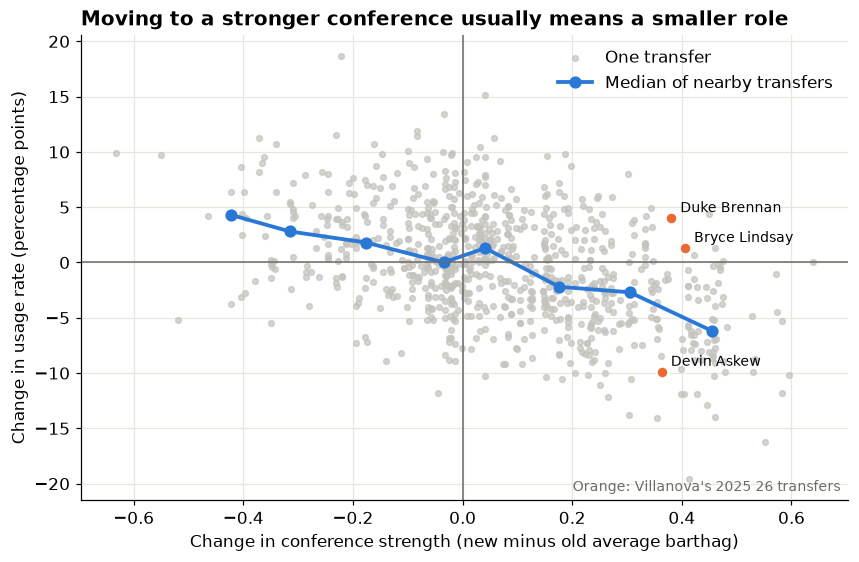

In [14]:
fig, ax = plt.subplots()
ax.scatter(transfers["strength_change"], transfers["usage_change"], s=14, color=GRAY, alpha=0.7, label="One transfer")

# median usage change within bins of strength change, to show the trend through the cloud
bins = pd.cut(transfers["strength_change"], bins=[-0.8, -0.4, -0.25, -0.1, 0, 0.1, 0.25, 0.4, 0.8])
trend = transfers.groupby(bins, observed=True).agg(x=("strength_change", "median"), y=("usage_change", "median"))
ax.plot(trend["x"], trend["y"], color=BLUE, linewidth=2.5, marker="o", markersize=7, label="Median of nearby transfers")

for _, row in nova_transfers.iterrows():
    ax.scatter(row["strength_change"], row["usage_change"], s=60, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(row["player_name_26"], (row["strength_change"], row["usage_change"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.axhline(0, color=DARK_GRAY, linewidth=1)
ax.axvline(0, color=DARK_GRAY, linewidth=1)
ax.set_xlabel("Change in conference strength (new minus old average barthag)")
ax.set_ylabel("Change in usage rate (percentage points)")
ax.set_title("Moving to a stronger conference usually means a smaller role")
ax.text(0.99, 0.02, "Orange: Villanova's 2025 26 transfers", transform=ax.transAxes, ha="right", fontsize=9, color=DARK_GRAY)
ax.legend(loc="upper right", frameon=False)
plt.show()

**Caption:** Each gray dot is one of the 826 players who transferred and played at least 20% of minutes in both seasons. The blue line traces the median change in usage across the range of conference strength changes, and it slopes clearly downward, players who moved about 0.4 rating points down gained about 4 points of usage, while those who moved a similar amount up lost about 6. Villanova's three transfers all moved up from mid major conferences. Devin Askew followed the trend, dropping from a 31% usage star at Long Beach State to a 21% role player. Duke Brennan and Bryce Lindsay actually took on more of the offense despite the jump, which is a positive scouting signal.

### Figure 2: Comparing transfers to players who stayed

The scatter plot shows a trend, but most players naturally improve with age. To separate the effect of transferring from normal growth, this view compares the median change for each transfer group against players who stayed at the same school, across all three stats.

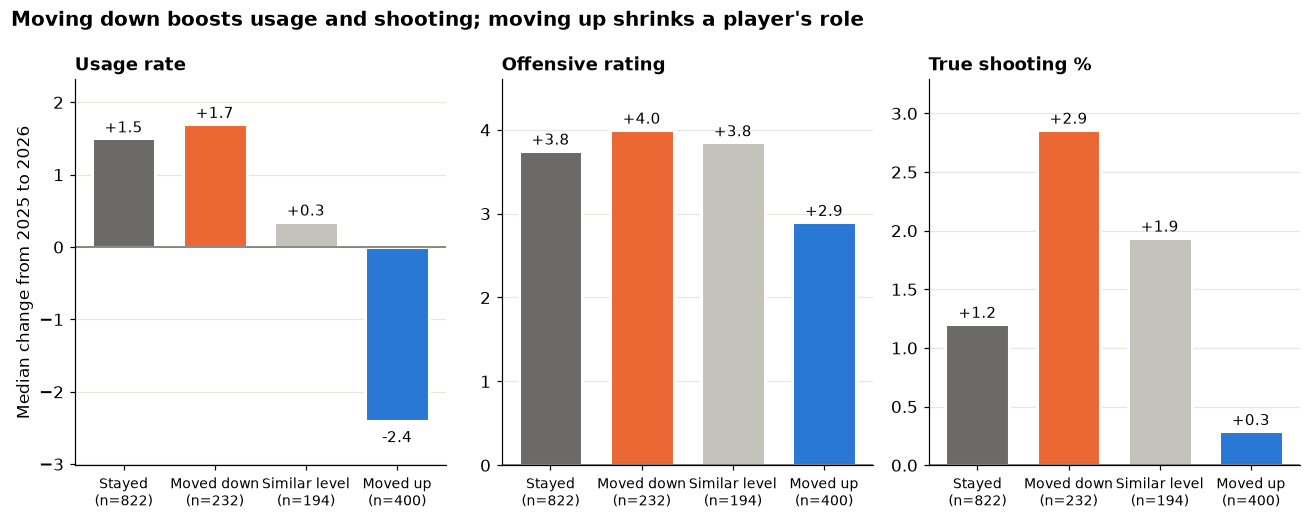

In [15]:
order = ["Stayed", "Moved down", "Similar level", "Moved up"]
colors = [DARK_GRAY, ORANGE, GRAY, BLUE]
stats = {"usage_change": "Usage rate", "o_rtg_change": "Offensive rating", "ts_pct_change": "True shooting %"}
medians = both.groupby("group")[list(stats)].median().loc[order]
counts = both["group"].value_counts().loc[order]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), sharey=False)
for ax, (col, label) in zip(axes, stats.items()):
    bars = ax.bar(range(4), medians[col], color=colors, width=0.7, edgecolor="white", linewidth=2)
    ax.axhline(0, color=DARK_GRAY, linewidth=1)
    for i, v in enumerate(medians[col]):
        ax.annotate(f"{v:+.1f}", (i, v), xytext=(0, 4 if v >= 0 else -14), textcoords="offset points",
                    ha="center", fontsize=10)
    ax.set_xticks(range(4), [f"{g}\n(n={counts[g]})" for g in order], fontsize=9)
    ax.set_title(label, fontsize=12)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
axes[0].set_ylabel("Median change from 2025 to 2026")
fig.suptitle("Moving down boosts usage and shooting; moving up shrinks a player's role",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**Caption:** Each panel shows the median change from 2025 to 2026 for one stat, with players who stayed at the same school as the baseline. Players who stayed grew their usage by 1.5 points, but players who moved up lost 2.4, and their true shooting barely improved. Moving down produced the biggest shooting gains (+2.9). Offensive rating improved by roughly the same amount in every group, which suggests transfers who move up keep their efficiency by taking fewer and easier shots. This view only includes players who kept a regular role in both seasons, so players who moved up and lost their spot entirely are missing, and moving up is probably even harder than it looks here.

## Question 2: How stable is a team's style from one season to the next?

**Approach.** I measure two parts of style:

* **Pace:** `adjt` from the team results files.
* **Three point rate:** the share of a team's field goal attempts that are threes. The team files do not have this, so I build it by adding up the attempts of every player on the team.

**Roster continuity** is the percent of a team's 2026 minutes played by players who were on the same team in 2025. The code uses `groupby("team")`, which splits the players into one group per team. Then `.sum()` adds up each column within each group.

In [16]:
def three_point_rate(players):
    totals = players.groupby("team")[["three_pa", "two_pa"]].sum()
    return totals["three_pa"] / (totals["three_pa"] + totals["two_pa"]) * 100

# mark each 2026 player as a returner if he was on the same team in 2025
last_team = players_2025[["player_id", "team"]].rename(columns={"team": "team_2025"})
p26 = players_2026.merge(last_team, on="player_id", how="left")
p26["returning_min"] = p26["min_pct"].where(p26["team_2025"] == p26["team"], 0)
team_minutes = p26.groupby("team")[["returning_min", "min_pct"]].sum()

style = pd.DataFrame({
    "three_rate_25": three_point_rate(players_2025),
    "three_rate_26": three_point_rate(players_2026),
    "pace_25": teams_2025.set_index("team")["adjt"],
    "pace_26": teams_2026.set_index("team")["adjt"],
    "continuity": team_minutes["returning_min"] / team_minutes["min_pct"] * 100,
}).dropna()   # drops teams that were not in Division I both years

print(len(style), "teams")
print("Correlation of three point rate across seasons:", round(style["three_rate_25"].corr(style["three_rate_26"]), 2))
print("Correlation of pace across seasons:", round(style["pace_25"].corr(style["pace_26"]), 2))
style.loc[["Villanova", "Maryland"]].round(1)

364 teams
Correlation of three point rate across seasons: 0.6
Correlation of pace across seasons: 0.45


,three_rate_25,three_rate_26,pace_25,pace_26,continuity
team,,,,,
Villanova,43.7,45.7,63.5,65.1,14.8
Maryland,35.4,46.9,69.7,66.5,0.0


### Figure 3: Three point rate carries over more than pace

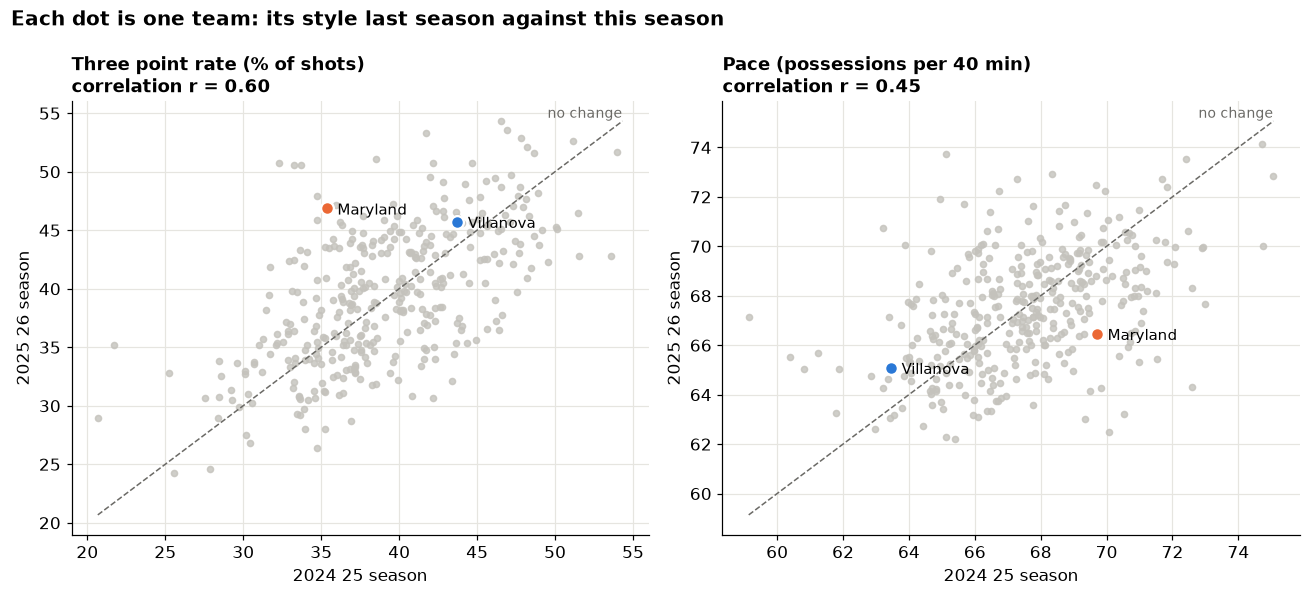

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
panels = [("three_rate", "Three point rate (% of shots)"), ("pace", "Pace (possessions per 40 min)")]
for ax, (stat, label) in zip(axes, panels):
    x, y = style[stat + "_25"], style[stat + "_26"]
    ax.scatter(x, y, s=16, color=GRAY, alpha=0.8)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], color=DARK_GRAY, linestyle="--", linewidth=1)
    ax.text(hi, hi, " no change", fontsize=9, color=DARK_GRAY, va="bottom", ha="right")
    for team, color in [("Villanova", BLUE), ("Maryland", ORANGE)]:
        ax.scatter(x[team], y[team], s=70, color=color, edgecolor="white", linewidth=1.5, zorder=3)
        ax.annotate(team, (x[team], y[team]), xytext=(7, -4), textcoords="offset points", fontsize=10)
    ax.set_xlabel(f"2024 25 season")
    ax.set_ylabel(f"2025 26 season")
    ax.set_title(f"{label}\ncorrelation r = {x.corr(y):.2f}", fontsize=12)
fig.suptitle("Each dot is one team: its style last season against this season",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**Caption:** Each dot is one of 364 teams, plotted by its style last season (x axis) against this season (y axis); dots on the dashed line did not change at all. Three point rate is fairly stable from year to year (correlation 0.60), while pace is noticeably less stable (0.45), so a team's shot selection seems to be more of a program identity than how fast it plays. Villanova sits close to the line on both measures. Maryland, which lost its coach to Villanova, jumped from a 35% to a 47% three point rate, the 8th largest change of all 364 teams.

### Figure 4: Does roster turnover make style less stable?

To refine Figure 3, I split teams into three equal sized groups by roster continuity. For each group I show how much style changed, as the median absolute change (the size of the change, ignoring whether it went up or down).

,returning,three_rate_shift,pace_shift,teams
continuity_group,,,,
Low continuity,11.6,3.8,2.2,122
Middle,34.2,3.9,1.4,121
High continuity,57.3,2.7,1.1,121


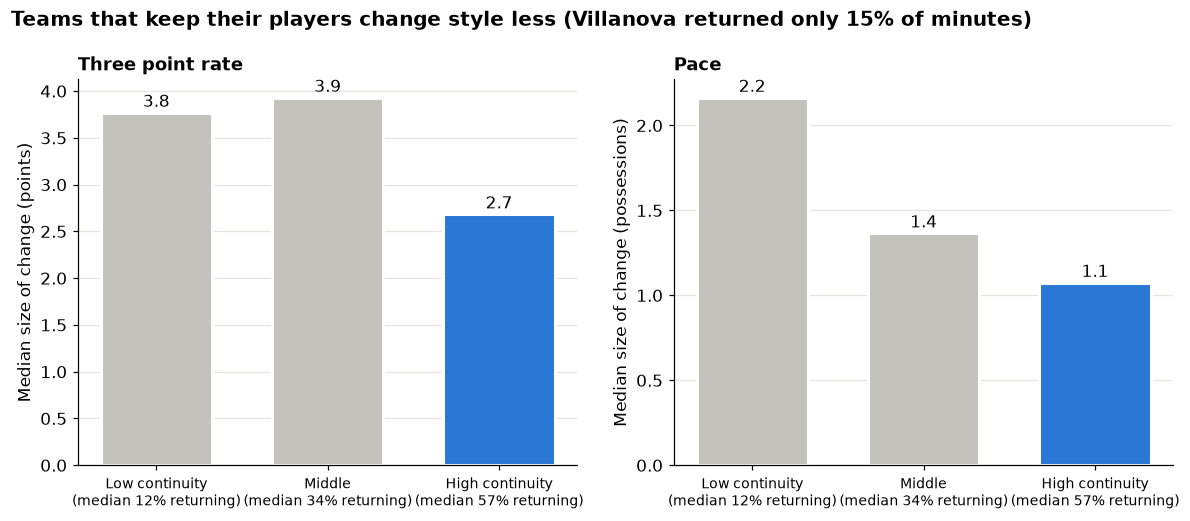

In [18]:
style["continuity_group"] = pd.qcut(style["continuity"], 3, labels=["Low continuity", "Middle", "High continuity"])
style["three_rate_shift"] = (style["three_rate_26"] - style["three_rate_25"]).abs()
style["pace_shift"] = (style["pace_26"] - style["pace_25"]).abs()

summary = style.groupby("continuity_group", observed=True).agg(
    returning=("continuity", "median"),
    three_rate_shift=("three_rate_shift", "median"),
    pace_shift=("pace_shift", "median"),
    teams=("continuity", "size"))
display(summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
labels = [f"{g}\n(median {r:.0f}% returning)" for g, r in zip(summary.index, summary["returning"])]
for ax, col, title, unit in [(axes[0], "three_rate_shift", "Three point rate", "points"),
                             (axes[1], "pace_shift", "Pace", "possessions")]:
    ax.bar(range(3), summary[col], color=[GRAY, GRAY, BLUE], width=0.65, edgecolor="white", linewidth=2)
    for i, v in enumerate(summary[col]):
        ax.annotate(f"{v:.1f}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center")
    ax.set_xticks(range(3), labels, fontsize=9)
    ax.set_ylabel(f"Median size of change ({unit})")
    ax.set_title(title, fontsize=12)
    ax.grid(axis="x", visible=False)
nova = style.loc["Villanova"]
fig.suptitle(f"Teams that keep their players change style less (Villanova returned only {nova['continuity']:.0f}% of minutes)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**Caption:** Teams are split into three equal groups by the share of 2026 minutes played by returning players, and each bar shows how much style changed for the typical team in that group. Teams in the high continuity group changed their three point rate by 2.7 points and their pace by 1.1 possessions, compared with 3.8 points and 2.2 possessions for teams that turned over most of their roster. Roster turnover roughly doubles how much pace moves, but its effect on three point rate only appears once a team keeps most of its players. Villanova is an exception: it returned only 15% of its minutes yet changed its three point rate by just 2.0 points and its pace by 1.6.

### Figure 5: Case study: did Kevin Willard's style follow him from Maryland to Villanova?

Kevin Willard coached Maryland in 2024 25 and was hired by Villanova in March 2025, replacing Kyle Neptune. (This coaching information is not in the Torvik files; it comes from public news coverage of the hire.) Three of his Maryland players followed him: Malachi Palmer, Tafara Gapare and Braden Pierce. If coaches carry a style, Villanova 2025 26 should look like Maryland 2024 25.

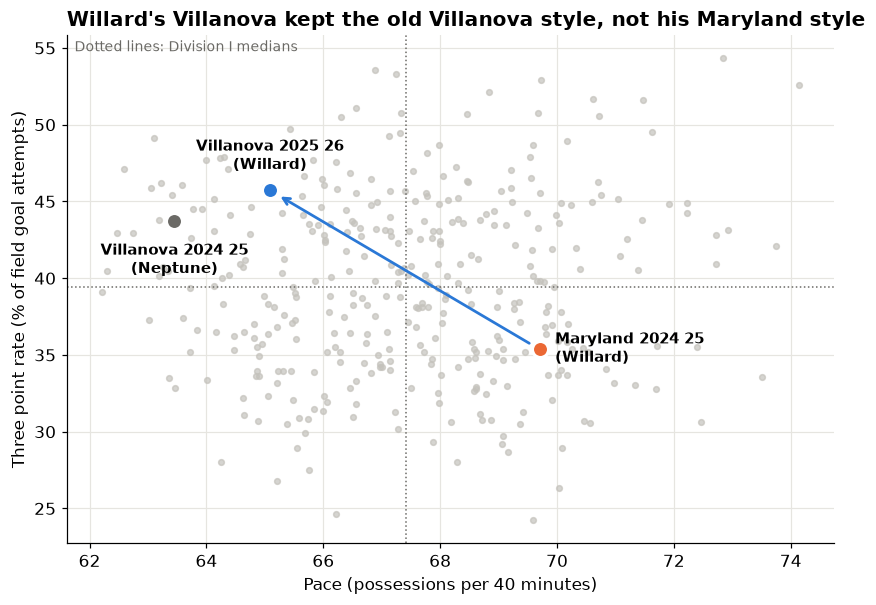

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(style["pace_26"], style["three_rate_26"], s=14, color=GRAY, alpha=0.7, label="Every team, 2025 26")
ax.axvline(style["pace_26"].median(), color=DARK_GRAY, linewidth=1, linestyle=":")
ax.axhline(style["three_rate_26"].median(), color=DARK_GRAY, linewidth=1, linestyle=":")

points = {
    "Maryland 2024 25\n(Willard)": (style.loc["Maryland", "pace_25"], style.loc["Maryland", "three_rate_25"], ORANGE),
    "Villanova 2024 25\n(Neptune)": (style.loc["Villanova", "pace_25"], style.loc["Villanova", "three_rate_25"], DARK_GRAY),
    "Villanova 2025 26\n(Willard)": (style.loc["Villanova", "pace_26"], style.loc["Villanova", "three_rate_26"], BLUE),
}
offsets = {"Maryland 2024 25\n(Willard)": (10, -8, "left"),
           "Villanova 2024 25\n(Neptune)": (0, -34, "center"),
           "Villanova 2025 26\n(Willard)": (0, 14, "center")}
for name, (x, y, color) in points.items():
    ax.scatter(x, y, s=110, color=color, edgecolor="white", linewidth=2, zorder=3)
    dx, dy, ha = offsets[name]
    ax.annotate(name, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=10, fontweight="bold", ha=ha)

(mx, my, _), (vx, vy, _) = points["Maryland 2024 25\n(Willard)"], points["Villanova 2025 26\n(Willard)"]
ax.annotate("", xy=(vx, vy), xytext=(mx, my),
            arrowprops=dict(arrowstyle="->", color=BLUE, linewidth=1.8, shrinkA=8, shrinkB=8))

ax.text(0.01, 0.99, "Dotted lines: Division I medians", transform=ax.transAxes, va="top", fontsize=9, color=DARK_GRAY)
ax.set_xlabel("Pace (possessions per 40 minutes)")
ax.set_ylabel("Three point rate (% of field goal attempts)")
ax.set_title("Willard's Villanova kept the old Villanova style, not his Maryland style")
plt.show()

**Caption:** Each gray dot is a Division I team in 2025 26, placed by pace and three point rate, with dotted lines at the national medians. If coaches carried their style with them, Villanova 2025 26 (blue) would land near Willard's 2024 25 Maryland team (orange), a fast team that rarely shot threes. Instead, Willard's Villanova was slow and three heavy, landing right next to Kyle Neptune's 2024 25 Villanova team (dark gray), even though only 15% of Villanova's minutes came from returning players. This is a single example, so it cannot prove a rule, but it suggests Willard adapted to his new roster rather than forcing his old system onto it.

## Question 3: How does Villanova's roster compare to the Big East and ACC?

**Approach.** For shot profile, I add up every player's rim, midrange and three point attempts for each team, and turn them into shares of the team's total. I then average those shares across the other Big East teams and across the ACC teams. For experience, I use a **minutes weighted average age**, where players who play more count more. It answers "how old is the team that is actually on the floor?" 

In [20]:
shots = players_2026.groupby(["team", "conf"])[["rim_attempts", "mid_attempts", "three_pa"]].sum()
total = shots.sum(axis=1)
shot_share = shots.div(total, axis=0).mul(100).reset_index()
shot_share.columns = ["team", "conf", "Rim", "Midrange", "Three"]
shot_share = shot_share[shot_share["conf"].isin(["BE", "ACC"])]

nova_shots = shot_share[shot_share["team"] == "Villanova"]
groups = pd.DataFrame({
    "Villanova": nova_shots[["Rim", "Midrange", "Three"]].iloc[0],
    "Rest of Big East": shot_share[(shot_share["conf"] == "BE") & (shot_share["team"] != "Villanova")][["Rim", "Midrange", "Three"]].mean(),
    "ACC": shot_share[shot_share["conf"] == "ACC"][["Rim", "Midrange", "Three"]].mean(),
}).T
groups.round(1)

,Rim,Midrange,Three
Villanova,35.2,19.0,45.7
Rest of Big East,40.3,21.3,38.3
ACC,37.2,20.6,42.2


### Figure 6: Villanova's shot profile against the conference averages

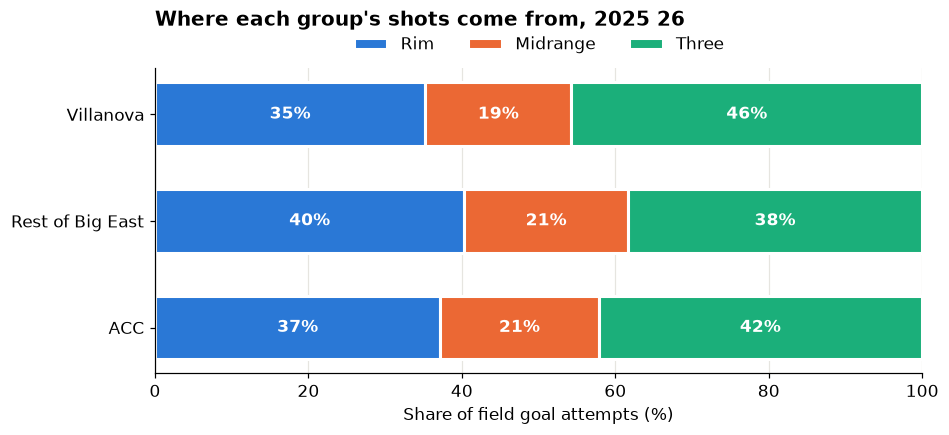

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0.0, index=groups.index)
for zone, color in [("Rim", BLUE), ("Midrange", ORANGE), ("Three", AQUA)]:
    ax.barh(groups.index, groups[zone], left=left, color=color, edgecolor="white", linewidth=2, height=0.6, label=zone)
    for i, (team, v) in enumerate(groups[zone].items()):
        ax.text(left[team] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += groups[zone]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of field goal attempts (%)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Where each group's shots come from, 2025 26", pad=28)
plt.show()

**Caption:** Each bar splits a group's field goal attempts into rim, midrange and three point shots for the 2025 26 season. Villanova takes 46% of its shots from three, well above the rest of the Big East (38%) and the ACC (42%). It makes up for this mainly with fewer rim attempts (35% against 40% for the Big East). For an opponent's scouting report, this means Villanova lives and dies by the three, and running shooters off the line matters more than protecting the rim.

### Figure 7: Every Big East and ACC team, with Villanova highlighted

Averages can hide a lot of spread. This refined view plots each team's rim share against its three point share, so Villanova can be compared to individual teams rather than only to the averages.

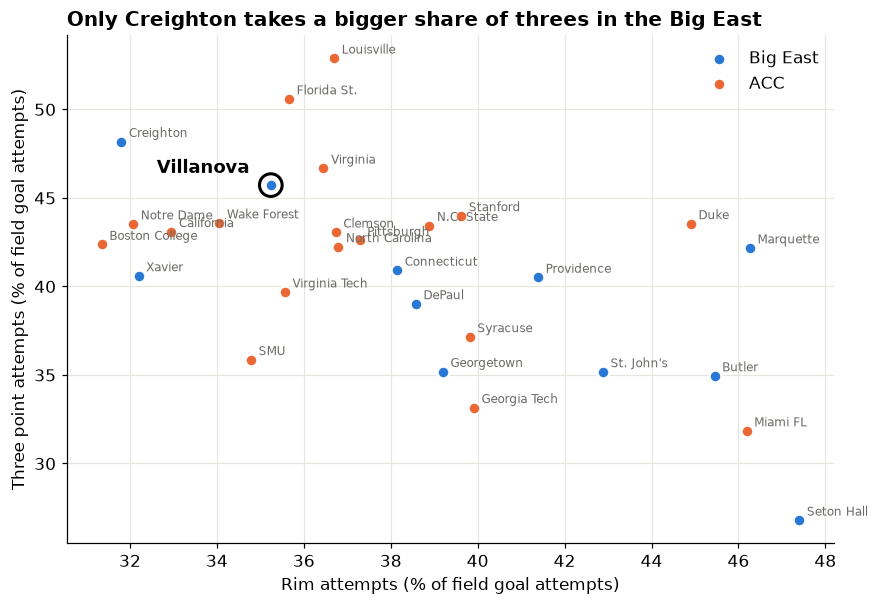

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
for conf, color, name in [("BE", BLUE, "Big East"), ("ACC", ORANGE, "ACC")]:
    sub = shot_share[shot_share["conf"] == conf]
    ax.scatter(sub["Rim"], sub["Three"], s=60, color=color, edgecolor="white", linewidth=1.5, label=name, zorder=2)
    for _, row in sub.iterrows():
        if row["team"] != "Villanova":
            ax.annotate(row["team"], (row["Rim"], row["Three"]), xytext=(5, 3), textcoords="offset points",
                        fontsize=8, color=DARK_GRAY)

nova_row = shot_share[shot_share["team"] == "Villanova"].iloc[0]
ax.scatter(nova_row["Rim"], nova_row["Three"], s=220, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
ax.annotate("Villanova", (nova_row["Rim"], nova_row["Three"]), xytext=(-14, 8), textcoords="offset points",
            fontsize=12, fontweight="bold", ha="right")
ax.set_xlabel("Rim attempts (% of field goal attempts)")
ax.set_ylabel("Three point attempts (% of field goal attempts)")
ax.set_title("Only Creighton takes a bigger share of threes in the Big East")
ax.legend(frameon=False, loc="upper right")
plt.show()

**Caption:** Each dot is a Big East (blue) or ACC (orange) team, with rim attempt share on the x axis and three point share on the y axis; Villanova is circled. Only Creighton takes a larger share of threes in the Big East, and only Creighton and Xavier take a smaller share at the rim. The chart also shows that the two conferences overlap heavily, so conference membership says little about style. Villanova's closest stylistic matches are ACC teams such as Virginia and Wake Forest rather than its Big East rivals.

### Figure 8: Experience: how old is each team's rotation?

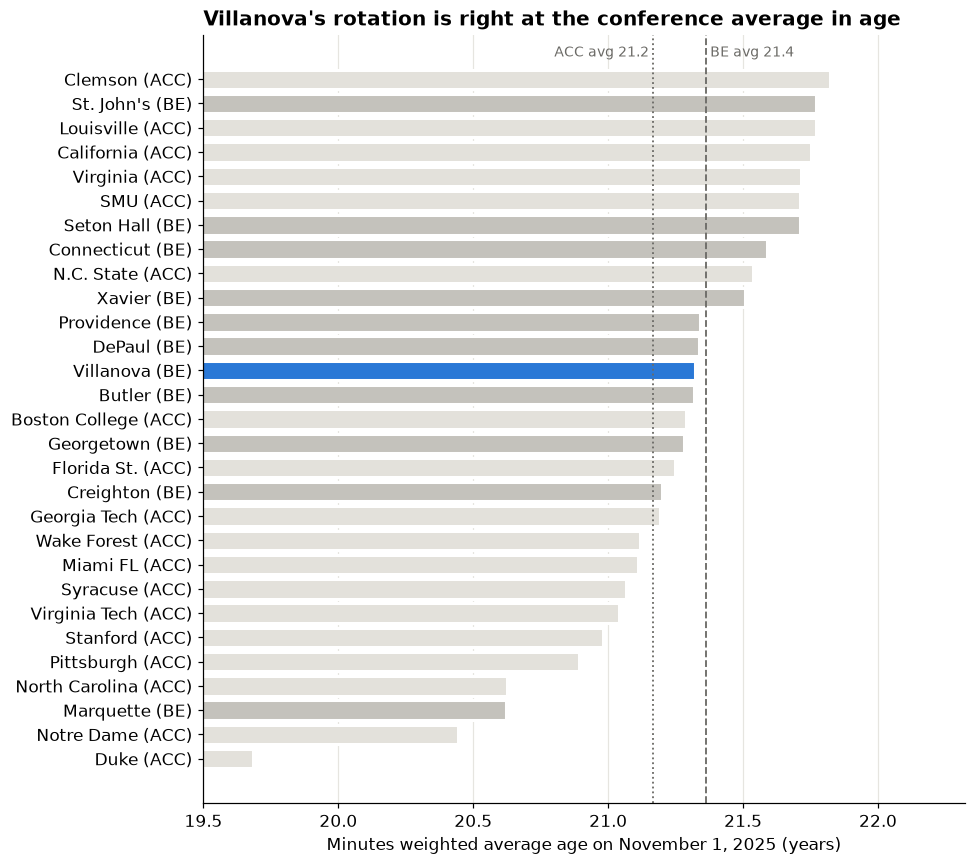

In [23]:
def weighted_age(group):
    g = group.dropna(subset=["age"])
    return (g["age"] * g["min_pct"]).sum() / g["min_pct"].sum()

conf_players = players_2026[players_2026["conf"].isin(["BE", "ACC"])]
ages = conf_players.groupby(["team", "conf"])[["age", "min_pct"]].apply(weighted_age).rename("age").reset_index()
ages = ages.sort_values("age")
conf_avg = ages.groupby("conf")["age"].mean()

fig, ax = plt.subplots(figsize=(9, 8))
colors = [BLUE if t == "Villanova" else (GRAY if c == "BE" else "#e3e1db") for t, c in zip(ages["team"], ages["conf"])]
ax.barh(ages["team"] + " (" + ages["conf"] + ")", ages["age"], color=colors, edgecolor="white", linewidth=2, height=0.8)
for conf, style_, ha in [("BE", "--", "left"), ("ACC", ":", "right")]:
    ax.axvline(conf_avg[conf], color=DARK_GRAY, linestyle=style_, linewidth=1.2)
    ax.text(conf_avg[conf], len(ages) - 0.2, f" {conf} avg {conf_avg[conf]:.1f} ", fontsize=9, color=DARK_GRAY, va="bottom", ha=ha)
ax.set_xlim(19.5, ages["age"].max() + 0.5)
ax.set_xlabel("Minutes weighted average age on November 1, 2025 (years)")
ax.grid(axis="y", visible=False)
ax.set_title("Villanova's rotation is right at the conference average in age")
plt.tight_layout()
plt.show()

**Caption:** Each bar is a team's average age weighted by minutes played, so players who play more count more; the dashed and dotted lines are the Big East (21.4) and ACC (21.2) averages. Villanova's rotation averages 21.3 years old, almost exactly the conference norm. That average hides a mix: older transfers such as Duke Brennan and Devin Askew alongside freshman point guard Acaden Lewis, who played 75% of the minutes. The range across both conferences is wide, from a veteran Clemson team (21.8) to a very young Duke team (19.7).

### Figure 9: Who returns for 2026 27?

There is no 2026 27 data yet, so I treat every non senior on this season's roster as returning. This ignores players who may transfer out and players who will arrive. It answers how much of this season's production is already on campus for next season.

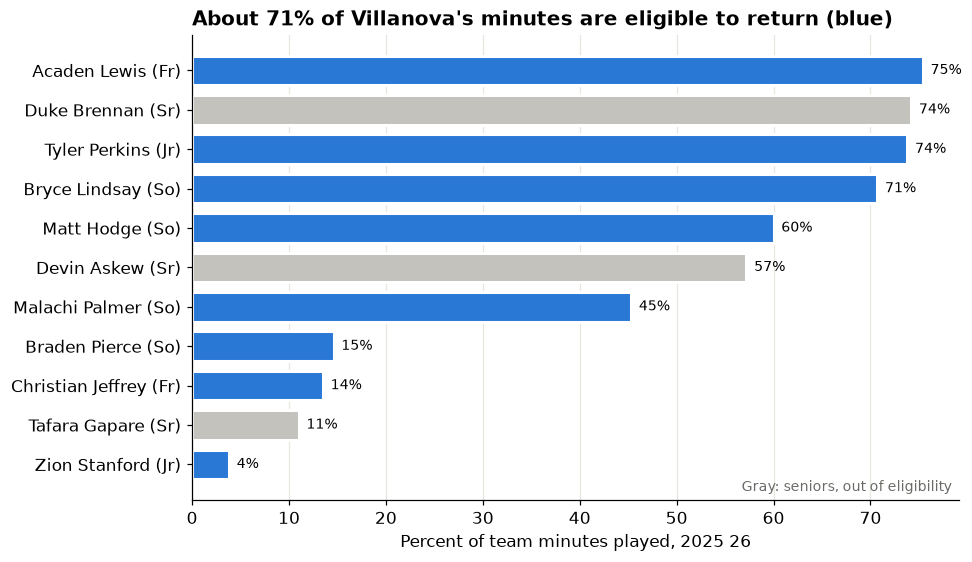

team
Georgetown     78.0
Villanova      71.0
Marquette      71.0
Creighton      70.0
Butler         65.0
Connecticut    61.0
Seton Hall     60.0
Providence     56.0
DePaul         53.0
St. John's     39.0
Xavier         33.0
Name: % of minutes eligible to return, dtype: float64

In [24]:
nova = players_2026[players_2026["team"] == "Villanova"].sort_values("min_pct")
nova = nova[nova["min_pct"] >= 1]
returning = nova["class"] != "Sr"

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(nova["player_name"] + " (" + nova["class"] + ")", nova["min_pct"],
        color=[BLUE if r else GRAY for r in returning], edgecolor="white", linewidth=2, height=0.75)
for y, (v, r) in enumerate(zip(nova["min_pct"], returning)):
    ax.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Percent of team minutes played, 2025 26")
ax.grid(axis="y", visible=False)

share_back = nova.loc[returning, "min_pct"].sum() / nova["min_pct"].sum() * 100
ax.set_title(f"About {share_back:.0f}% of Villanova's minutes are eligible to return (blue)")
ax.text(0.99, 0.02, "Gray: seniors, out of eligibility", transform=ax.transAxes, ha="right", fontsize=9, color=DARK_GRAY)
plt.show()

# how does that compare to the rest of the Big East?
be = players_2026[players_2026["conf"] == "BE"].copy()
be["non_senior_min"] = be["min_pct"].where(be["class"] != "Sr", 0)
be_back = be.groupby("team")[["non_senior_min", "min_pct"]].sum()
(be_back["non_senior_min"] / be_back["min_pct"] * 100).sort_values(ascending=False).round(0).rename("% of minutes eligible to return")

**Caption:** Each bar is one Villanova player's share of team minutes in 2025 26; blue players have eligibility left and gray players are seniors. About 71% of Villanova's minutes are eligible to return, tied with Marquette for second in the Big East behind Georgetown (78%), so Villanova should have one of the most experienced cores in the conference next season. The biggest loss is center Duke Brennan, who took 181 rim attempts and no threes. Without him, Villanova's already perimeter heavy shot profile may tilt even further toward the three unless a new big man arrives. This view cannot account for players transferring in or out, which is common in the portal era.

## Summary of lessons learned

1. **Moving up costs a player his role.** Transfers who move to a stronger conference lose about 2.4 points of usage, while players who stay at their school gain about 1.5. Moving down produces the biggest shooting gains. Offensive rating improves by a similar amount in every group, so players who move up stay efficient by taking a smaller, easier share of the offense. For Villanova, Duke Brennan and Bryce Lindsay beat this trend by taking on more of the offense after moving up.
2. **Shot selection is more stable than pace.** A team's three point rate carries over from season to season (correlation 0.60) more than its pace does (0.45). Heavy roster turnover roughly doubles how much pace changes.
3. **Coaches do not simply bring their style with them.** In the Kevin Willard case study, Villanova kept the slow, three heavy identity it had under Kyle Neptune instead of adopting Willard's faster, inside focused Maryland style, even though almost the whole roster was new. This is a single example, but it suggests coaches adapt to personnel.
4. **Villanova is a three point team.** It takes 46% of its shots from three, more than every Big East team except Creighton, and fewer shots at the rim than almost anyone in the conference. Its rotation is right at the conference average in age.
5. **Villanova's core mostly returns for 2026 27.** About 71% of its minutes are eligible to return, one of the highest shares in the Big East. Losing center Duke Brennan could push the shot profile even further toward the perimeter.

**Limitations.** The data covers only two seasons, so each comparison is a single year's change. Conference strength is a simple average of team ratings. The transfer analysis only includes players who kept a regular role in both seasons. Coaching information comes from outside the dataset and covers one coach. The 2026 27 roster is an estimate that ignores incoming players and transfers out.

**Next steps.** With more seasons of data, the coaching question could be tested across many coaching changes instead of one, and the 2026 27 roster could be updated once the season begins.